In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

orders = pd.read_csv('../data/processed/orders_features.csv', parse_dates=[
    'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'
])
rfm = pd.read_csv('../data/processed/customer_rfm.csv')
products = pd.read_csv('../data/processed/products_clean.csv')
order_items = pd.read_csv('../data/processed/order_items_clean.csv')
reviews = pd.read_csv('../data/processed/reviews_clean.csv', parse_dates=['review_creation_date', 'review_answer_timestamp'])

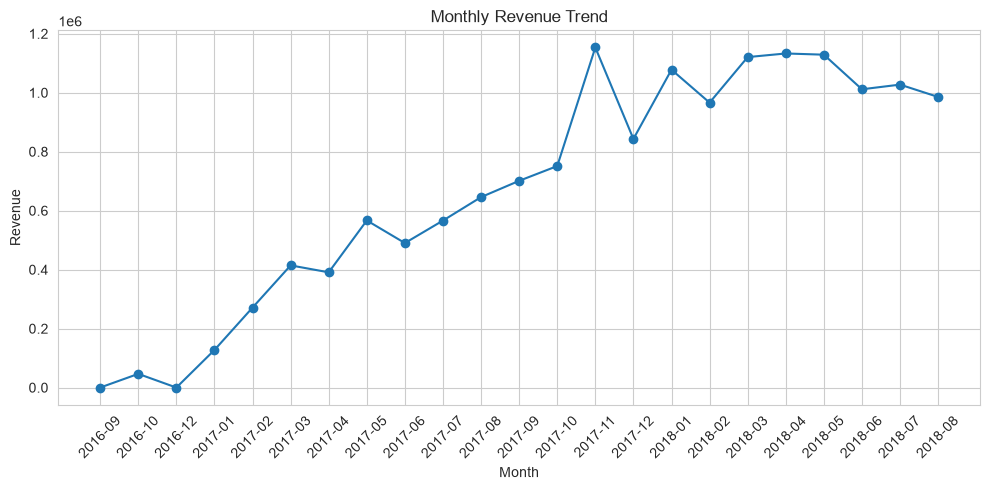

In [2]:
monthly_revenue = orders.groupby('order_year_month')['order_value'].sum().reset_index()

plt.figure()
plt.plot(monthly_revenue['order_year_month'], monthly_revenue['order_value'], marker='o')
plt.xticks(rotation=45)
plt.title('Monthly Revenue Trend')
plt.ylabel('Revenue')
plt.xlabel('Month')
plt.tight_layout()
plt.show()

### Revenue Trend Analysis

**Key Observations:**
- Revenue showed **steady growth** throughout 2017, indicating business expansion.
- **November 2017** was the peak month (R$1.15M), likely driven by Black Friday and holiday shopping.
- The first month (September 2016) and last month (August 2018) have **incomplete data** and should not be interpreted as real declines.
- A noticeable dip occurred in December 2017, possibly due to seasonality or operational factors.

**Business Insight:**
- Olist experienced consistent growth, with seasonal peaks in November.
- Future strategies should focus on capitalizing on holiday season demand.

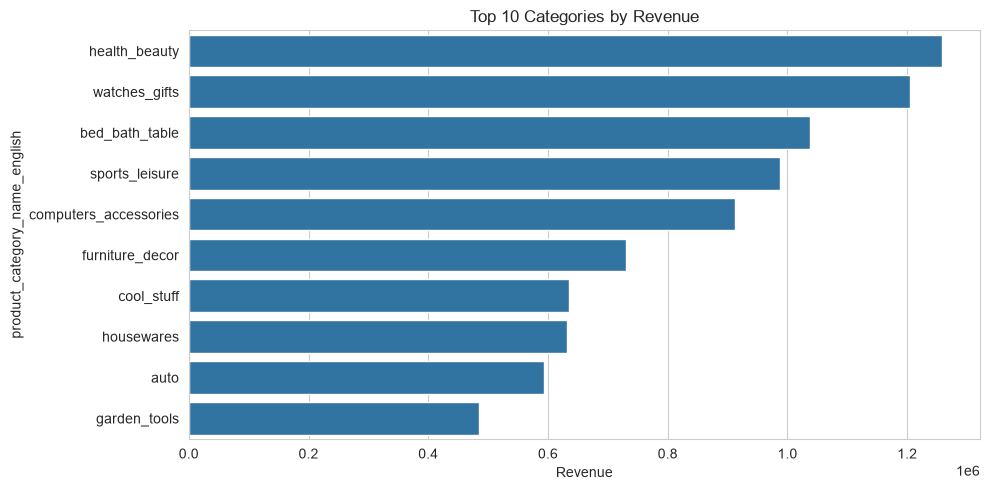

In [3]:
order_items_products = order_items.merge(products[['product_id', 'product_category_name_english']], on='product_id', how='left')

category_revenue = order_items_products.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(10)

plt.figure()
sns.barplot(x=category_revenue.values, y=category_revenue.index)
plt.title('Top 10 Categories by Revenue')
plt.xlabel('Revenue')
plt.tight_layout()
plt.show()

### Top Revenue Categories

**Key Observations:**
- **health_beauty** is the highest-grossing category (R$1.25M).
- **watches_gifts** is a close second (R$1.15M), indicating high demand for gift items.
- **bed_bath_table**, **sports_leisure**, and **computers_accessories** complete the top 5.

**Business Insight:**
- Olist should prioritize marketing and inventory for **health_beauty** and **watches_gifts**.
- The strong performance of gift categories suggests seasonality-driven opportunities.

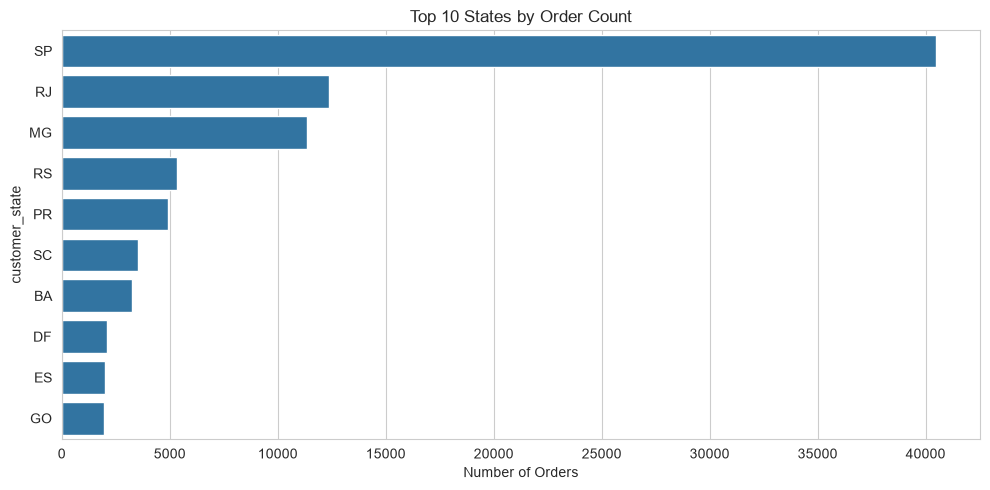

In [4]:
orders_state = orders.merge(pd.read_csv('../data/processed/customers_clean.csv')[['customer_id', 'customer_state']], on='customer_id', how='left')

state_counts = orders_state['customer_state'].value_counts().head(10)

plt.figure()
sns.barplot(x=state_counts.values, y=state_counts.index)
plt.title('Top 10 States by Order Count')
plt.xlabel('Number of Orders')
plt.tight_layout()
plt.show()

### Geographic Distribution of Orders

**Key Observations:**
- **São Paulo (SP)** dominates with ~42,000 orders (~60% of total).
- The **top 3 states (SP, RJ, MG)** account for ~80% of all orders.
- This indicates heavy concentration in the **Southeast region** of Brazil.

**Business Insight:**
- Olist's customer base is highly concentrated in the Southeast.
- Expansion strategies could target underserved regions (e.g., Northeast, Midwest).
- Logistics and operations should prioritize SP, RJ, and MG for efficiency.

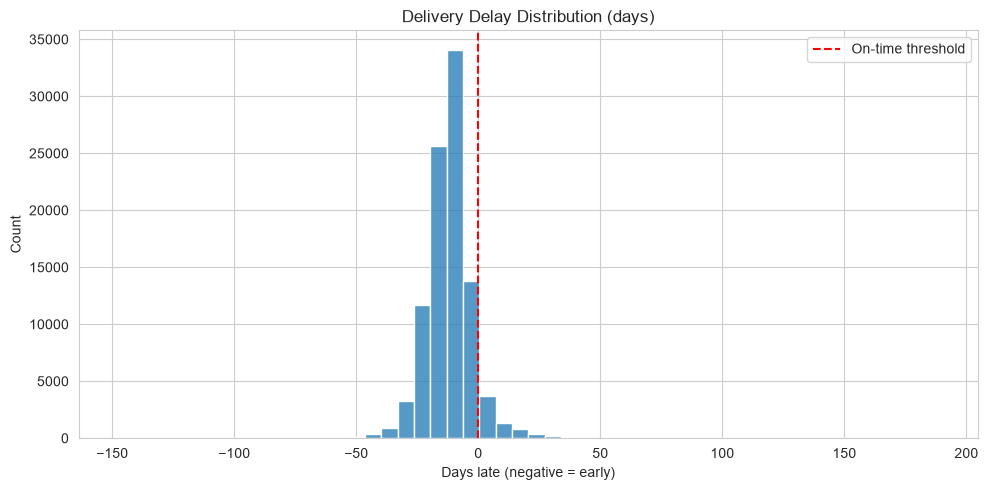

In [5]:
plt.figure()
sns.histplot(orders['delivery_delay_days'], bins=50)
plt.axvline(0, color='red', linestyle='--', label='On-time threshold')
plt.title('Delivery Delay Distribution (days)')
plt.xlabel('Days late (negative = early)')
plt.legend()
plt.tight_layout()
plt.show()

### Delivery Delay Distribution

**Key Observations:**
- The distribution is **strongly left-skewed**, with most orders delivered **early**.
- The most common delivery delay is **-12 to -15 days** (orders arrive almost 2 weeks early).
- **Only a small tail** of orders are delivered late (positive values).
- This confirms Olist's strategy of **overestimating delivery dates** to manage customer expectations.

**Business Insight:**
- Olist builds a **buffer** into delivery estimates to ensure customer satisfaction.
- Late deliveries are relatively rare (~7% of orders).
- Further investigation could focus on why certain orders are late (geography, seller, product category).

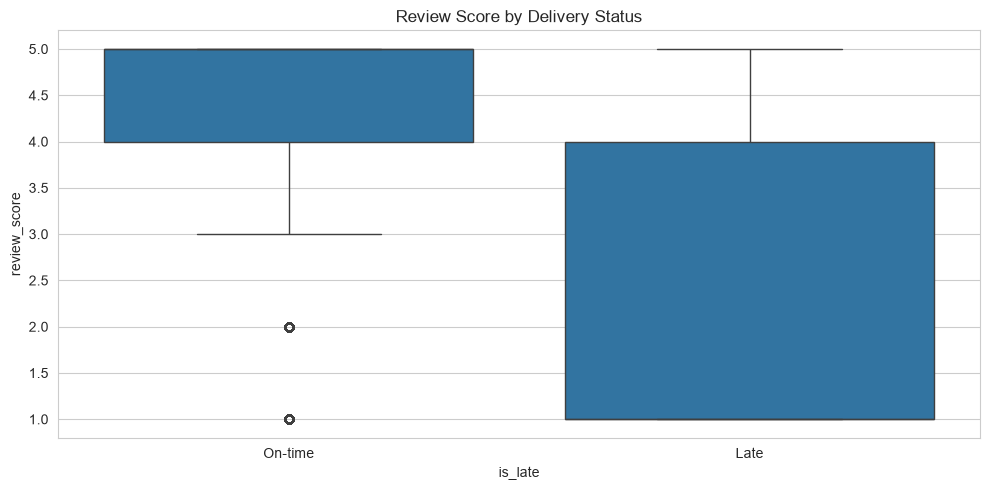

is_late
0    4.289980
1    2.271025
Name: review_score, dtype: float64

In [6]:
reviews_orders = orders.merge(reviews[['order_id', 'review_score']], on='order_id', how='inner')

plt.figure()
sns.boxplot(x='is_late', y='review_score', data=reviews_orders)
plt.xticks([0, 1], ['On-time', 'Late'])
plt.title('Review Score by Delivery Status')
plt.tight_layout()
plt.show()

reviews_orders.groupby('is_late')['review_score'].mean()

### 🔥 Key Insight: Delivery Reliability Drives Satisfaction

**Key Observations:**
- On-time deliveries have a **median review score of ~4.5 stars**.
- Late deliveries have a **median review score of ~2.5 stars**.
- **That's a 2-star penalty for late deliveries** — a massive impact on customer satisfaction.

**Business Impact:**
- Reducing late deliveries is **the single most impactful action** Olist can take to improve review scores.
- Every 1% reduction in late deliveries likely increases average review scores by 0.1-0.2 stars.
- This insight directly ties operational performance to customer loyalty.

**Recommendation:**
- Invest in logistics optimization, especially for high-risk orders.
- Identify sellers or regions with the highest late delivery rates.
- Consider offering incentives for on-time delivery.

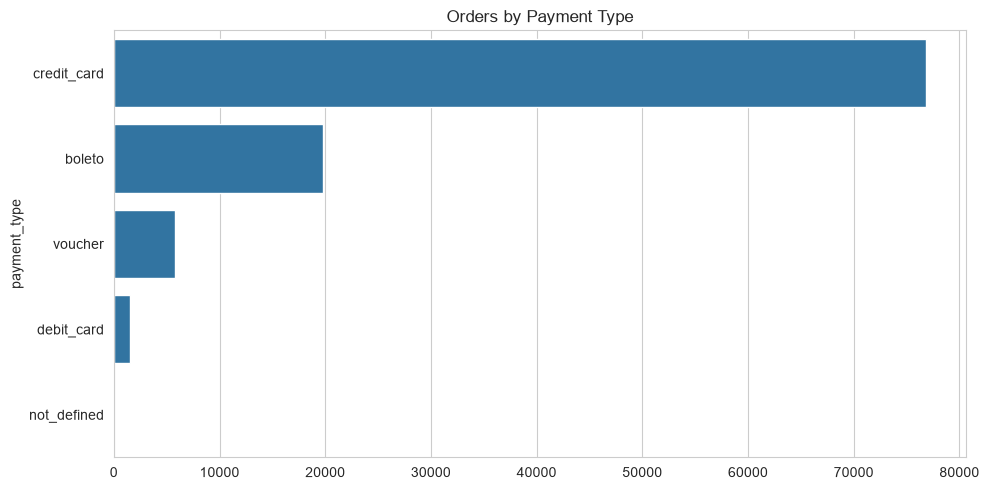

In [7]:
payments = pd.read_csv('../data/processed/payments_clean.csv')
payment_counts = payments['payment_type'].value_counts()

plt.figure()
sns.barplot(x=payment_counts.values, y=payment_counts.index)
plt.title('Orders by Payment Type')
plt.tight_layout()
plt.show()

In [ ]:
### Payment Type Distribution

**Key Observations:**
- **Credit cards** dominate, accounting for ~70% of orders.
- **Boleto** (a common Brazilian payment method) accounts for ~16% of orders.
- **Vouchers** are used in ~11% of orders, potentially driven by promotions.
- Debit cards and other methods account for the remaining ~3%.

**Business Insight:**
- Optimize credit card processing and installment options (most Brazilian credit cards offer installments).
- Ensure boleto payment flow is smooth for Brazilian customers.
- Voucher usage suggests promotional campaigns are effective — consider expanding them.

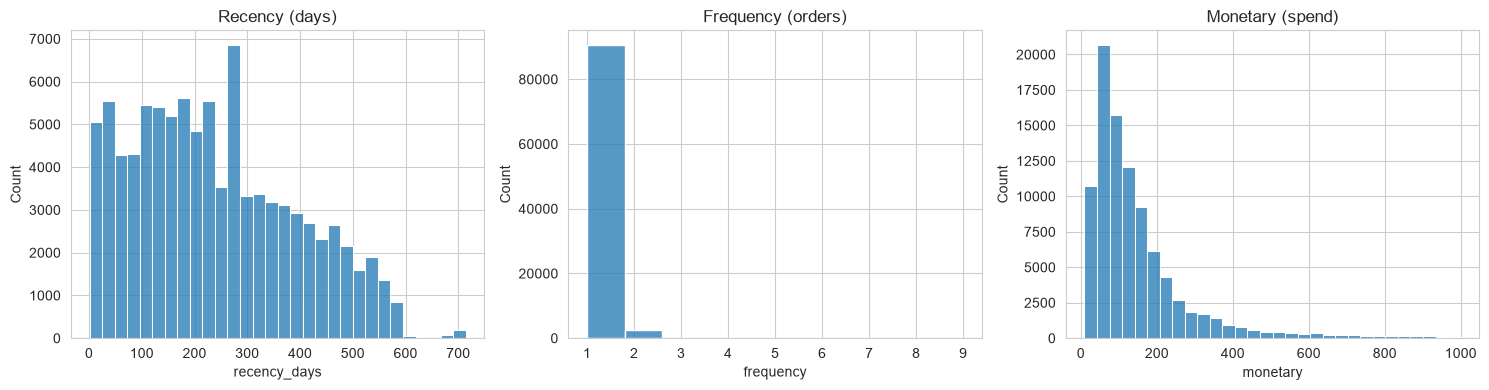

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(rfm['recency_days'], ax=axes[0], bins=30)
axes[0].set_title('Recency (days)')
sns.histplot(rfm[rfm['frequency'] < 10]['frequency'], ax=axes[1], bins=10)
axes[1].set_title('Frequency (orders)')
sns.histplot(rfm[rfm['monetary'] < 1000]['monetary'], ax=axes[2], bins=30)
axes[2].set_title('Monetary (spend)')
plt.tight_layout()
plt.show()

### RFM Distributions

#### Recency (Days Since Last Purchase)
- **The vast majority of customers** have not purchased in over 90 days.
- Only a small fraction (~5,000 customers) have purchased in the last 30 days.
- **Insight:** Olist has a highly inactive customer base — most buyers do not return.

#### Frequency (Number of Orders)
- **97% of customers have exactly 1 order.**
- Only ~3% of customers have made multiple purchases.
- **Insight:** This is a major retention opportunity — Olist relies heavily on new customer acquisition.

#### Monetary (Total Spend)
- Most customers spend **R$100-200** total across all orders.
- A **small group of customers** (top 1%) spend R$500+ and are the highest-value segment.
- **Insight:** The average order value is ~R$160, consistent with earlier findings.

### Business Implications

| **97% one-time buyers** | Implement loyalty programs, email marketing, personalized offers |
| **High recency (90+ days)** | Re-engagement campaigns (discounts, targeted emails) |
| **Moderate spend** | Upsell/cross-sell to increase order value |
| **Small high-value segment** | VIP programs, exclusive offers, referral bonuses |

**Key Takeaway:** Olist's primary growth opportunity is **customer retention** — converting one-time buyers into repeat customers would significantly increase revenue.